# Non-linear static analysis with the Newton-Raphson method

A non-linear static analysis finds the solution vector $\boldsymbol{c}$
whose internal force vector balances the external force vector scaled by
the load factor $\lambda$,

$$
\boldsymbol{R}(\boldsymbol{c}, \lambda) = \boldsymbol{F}_{int}(\boldsymbol{c})
- \lambda \boldsymbol{F}_{ext} = \boldsymbol{0}
$$

With [Analysis](../analysis.rst) it requires four callables, which calculate
the external force vector, the internal force vector, the constitutive
stiffness matrix $\boldsymbol{K}_C$ and the geometric stiffness matrix
$\boldsymbol{K}_G$. The Newton-Raphson method, `NL_method='NR'`, the
default, corrects the solution with the tangent stiffness matrix
$\boldsymbol{K}_T = \boldsymbol{K}_C + \boldsymbol{K}_G$,

$$
\boldsymbol{K}_T(\boldsymbol{c}_i)\, \Delta\boldsymbol{c} =
-\boldsymbol{R}(\boldsymbol{c}_i, \lambda), \qquad
\boldsymbol{c}_{i+1} = \boldsymbol{c}_i + \Delta\boldsymbol{c}
$$

until the residual $\boldsymbol{R}$ is small enough. When
$\boldsymbol{K}_T$ is the exact derivative of $\boldsymbol{F}_{int}$, the
convergence is quadratic (Crisfield 1991, Sections 1.2.2 and 1.2.3,
pp. 8-13). The load factor goes from zero to one in increments, see
[newton_raphson._solver_NR](../newton_raphson.rst).

**Reference.** Crisfield, M.A., Non-linear Finite Element Analysis of
Solids and Structures, Volume 1: Essentials, John Wiley & Sons, Chichester,
1991.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

from analytic_problems import Problem, convergence_orders

## Chain of hardening springs

The class `Problem` of `tests/analytic_problems.py`, used in the unit
tests, wraps an analytic problem into the four callables of
[Analysis](../analysis.rst), creates the analysis with its method
`analysis()`, and records the solution vector of every call to the internal
force vector, from which the iterations are counted.

The problem is a chain of four springs of stiffness 100 fixed at one end,
with a cubic hardening of each degree of freedom, loaded at the free end by
$P = 50$:

$$
\boldsymbol{F}_{int} = \boldsymbol{K} \boldsymbol{u} + \boldsymbol{a} \circ
\boldsymbol{u}^3, \qquad
\boldsymbol{K}_C = \boldsymbol{K}, \qquad
\boldsymbol{K}_G = \mathrm{diag}(3 \boldsymbol{a} \circ \boldsymbol{u}^2)
$$

with $\boldsymbol{a} = 50\,[1\ 2\ 3\ 4]^\top$, the cubes taken term by term
and $\boldsymbol{K}_C + \boldsymbol{K}_G$ the exact derivative of
$\boldsymbol{F}_{int}$. The function below is `hardening_springs` of
`tests/analytic_problems.py`:

In [2]:
def hardening_springs(P=50.):
    # chain of 4 springs with cubic hardening: fint = K u + a u**3
    n = 4
    K = 100.*(2*np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1))
    K[-1, -1] = 100.
    a = 50.*np.arange(1, n+1)
    fext = np.zeros(n)
    fext[-1] = P
    return Problem(fext, lambda u: K @ u + a*u**3, K,
                   lambda u: np.diag(3*a*u**2))

The reference solution of $\boldsymbol{R}(\boldsymbol{c}, \lambda) =
\boldsymbol{0}$ at any $\lambda$ is calculated independently with
`scipy.optimize.fsolve`, the hybrid Powell method of MINPACK, with its
Jacobian $\boldsymbol{K}_T$ and the relative tolerance `xtol=1e-13`, starting
from the linear solution:

In [3]:
def reference(p, lbd=1.):
    c0 = np.linalg.solve(p.kC, lbd*p.fext)
    return fsolve(lambda c: p.fint(c) - lbd*p.fext, c0,
                  fprime=lambda c: p.kC + p.kG(c), xtol=1e-13)

## Full load in one increment

With `initialInc=1.`, the full load is applied in a single increment,
starting from the linear solution
$\boldsymbol{K}_{C0}^{-1} \boldsymbol{F}_{ext}$. The relative error of each
iterate $\boldsymbol{c}_i$ against the reference $\boldsymbol{c}^*$, and the
order of convergence estimated by $\log e_{i+1}/\log e_i$ in the asymptotic
range ($10^{-13} < e_{i+1}$, $e_i < 10^{-2}$, `convergence_orders` of
`tests/analytic_problems.py`), show the quadratic convergence:

In [4]:
p = hardening_springs()
p.analysis(initialInc=1.)
p.an.static(NLgeom=True, silent=True)

ref = reference(p)
errors = [np.linalg.norm(c - ref)/np.linalg.norm(ref) for _, c in p.fint_calls]
orders = convergence_orders(errors)

print('increments:', p.an.increments)
print('calls to calc_fint:', len(p.fint_calls))
print()
print(f'{"call":>4s} {"||c_i - c*||/||c*||":>20s}')
for i, e in enumerate(errors):
    print(f'{i+1:4d} {e:20.3e}')
print()
print('estimated orders of convergence:', np.round(orders, 2))

increments: [1.0]
calls to calc_fint: 8

call  ||c_i - c*||/||c*||
   1            2.977e+00
   2            1.661e+00
   3            8.056e-01
   4            2.907e-01
   5            5.390e-02
   6            2.247e-03
   7            4.061e-06
   8            1.321e-11

estimated orders of convergence: [2.04 2.02]


The converged solution against the reference, with the relative
equilibrium residual
$\|\boldsymbol{R}\|/\|\lambda \boldsymbol{F}_{ext}\|$:

dof     u (Analysis)       u (fsolve) rel. diff.
  1   0.112250433936   0.112250433934    1.8e-11
  2   0.225208054582   0.225208054578    1.8e-11
  3   0.349587927744   0.349587927738    1.6e-11
  4   0.538053413406   0.538053413400    1.0e-11

||R||/||F_ext||, Analysis: 2.1866724013401447e-11
||R||/||F_ext||, fsolve: 9.431276279123788e-15


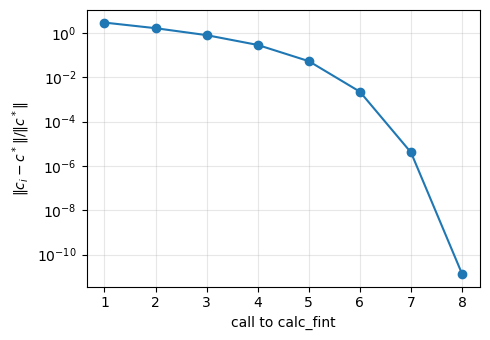

In [5]:
c = p.an.cs[-1]
print(f'{"dof":>3s} {"u (Analysis)":>16s} {"u (fsolve)":>16s} {"rel. diff.":>10s}')
for i in range(c.size):
    print(f'{i+1:3d} {c[i]:16.12f} {ref[i]:16.12f} {abs(c[i] - ref[i])/abs(ref[i]):10.1e}')
print()
for name, ci in [('Analysis', c), ('fsolve', ref)]:
    R = p.fint(ci) - p.fext
    print(f'||R||/||F_ext||, {name}:', np.linalg.norm(R)/np.linalg.norm(p.fext))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(np.arange(1, len(errors) + 1), errors, 'o-')
ax.set_xlabel('call to calc_fint')
ax.set_ylabel(r'$\|c_i - c^*\|/\|c^*\|$')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## Incremental analysis

The analysis can also be performed in increments, with `initialInc`
defining the size of the first load increment; the following increments
grow after a converged increment, limited by `maxInc`, and the last one
ends at the load factor 1. Each increment starts from a predictor
extrapolated from the previous converged increment. Each converged
increment against the reference at its load factor:

In [6]:
p = hardening_springs()
p.analysis(initialInc=0.1)
p.an.static(NLgeom=True, silent=True)

print('calls to calc_fint per increment:', p.calls_per_step())
print()
print(f'{"lambda":>8s} {"u_4 (Analysis)":>15s} {"u_4 (fsolve)":>15s}'
      f' {"max rel. diff. dofs":>20s}')
refs = []
for lbd, c in zip(p.an.increments, p.an.cs):
    r = reference(p, lbd)
    refs.append(r)
    print(f'{lbd:8.4f} {c[-1]:15.10f} {r[-1]:15.10f}'
          f' {np.max(np.abs(c - r)/np.abs(r)):20.1e}')

calls to calc_fint per increment: [5, 5, 5, 4, 4, 4, 4, 3]

  lambda  u_4 (Analysis)    u_4 (fsolve)  max rel. diff. dofs
  0.1000    0.1593569172    0.1593569172              1.6e-15
  0.2111    0.2560840154    0.2560840154              5.3e-12
  0.3346    0.3271712572    0.3271712572              3.7e-16
  0.4717    0.3864181446    0.3864181446              1.3e-11
  0.6241    0.4391026701    0.4391026701              2.7e-13
  0.7935    0.4877815686    0.4877815686              1.4e-14
  0.9816    0.5338981179    0.5338981179              3.0e-15
  1.0000    0.5380534134    0.5380534134              1.5e-13


The load-displacement curve of the loaded end hardens, departing from the
linear solution:

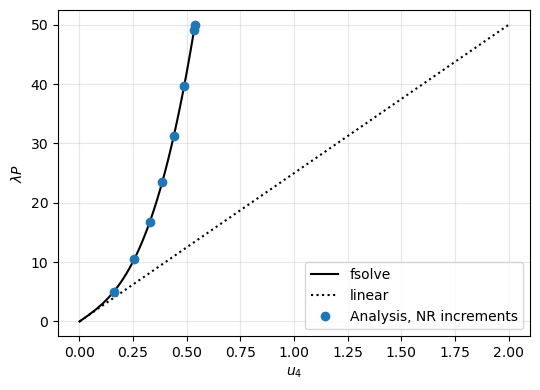

In [7]:
lbds = np.linspace(0., 1., 51)
u4_ref = [reference(p, l)[-1] if l > 0 else 0. for l in lbds]
u4_lin = np.linalg.solve(p.kC, p.fext)[-1]*lbds

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(u4_ref, lbds*p.fext[-1], 'k-', label='fsolve')
ax.plot(u4_lin, lbds*p.fext[-1], 'k:', label='linear')
ax.plot([c[-1] for c in p.an.cs], np.array(p.an.increments)*p.fext[-1],
        'o', label='Analysis, NR increments')
ax.set_xlabel('$u_4$')
ax.set_ylabel(r'$\lambda P$')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()